# P1 · ¿Qué tiempo hizo?

Datos diarios de la estación **A Coruña / Alvedro (aeropuerto)**, indicativo **08002**, del 1 de enero de 2021 al 31 de diciembre de 2025.

Pasos:

1. Descargar y guardar el fichero
2. Mirar el fichero antes de leerlo
3. Leer con pandas
4. Gráfica antes de limpiar
5. Limpiar
6. Guardar los datos limpios
7. Analizar
8. Gráficas
9. Eficiencia
10. PostgreSQL

> Ejecutar desde la carpeta `notebooks/` con *Kernel → Restart & Run All*.

## Paso 1. Descargar y guardar el fichero

Se descarga desde código y se guarda **sin modificar** en `datos/raw/` (se escriben los bytes tal cual llegan). Si las carpetas no existen, se crean.

In [1]:
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

URL = 'https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv'
RAIZ = Path('..')
RAW = RAIZ / 'datos' / 'raw' / 'meteo_alvedro_2021_2025.csv'
CLEAN = RAIZ / 'datos' / 'clean' / 'meteo_alvedro_limpio.csv'
OUTPUT = RAIZ / 'output'

for carpeta in [RAW.parent, CLEAN.parent, OUTPUT]:
    carpeta.mkdir(parents=True, exist_ok=True)

respuesta = requests.get(URL, timeout=60)
respuesta.raise_for_status()
RAW.write_bytes(respuesta.content)
print('Guardado en', RAW, '-', RAW.stat().st_size, 'bytes')
print('Fecha de descarga:', date.today())

Guardado en ../datos/raw/meteo_alvedro_2021_2025.csv - 81825 bytes
Fecha de descarga: 2026-10-27


## Paso 2. Mirar el fichero antes de leerlo

Primero los bytes, para saber la codificación.

In [2]:
contenido = RAW.read_bytes()
print(contenido[:200])

try:
    contenido.decode('utf-8')
    print('El fichero es UTF-8')
except UnicodeDecodeError as error:
    print('El fichero NO es UTF-8:', error)

b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\nEstaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo: 08002\nLatitude: 43,3000 \xb7 Lonxitude: -8,3833 \xb7 Altitude: 97 m\nPer\xedodo: 01/01/2021 - 31/12/2025\nFon'
El fichero NO es UTF-8: 'utf-8' codec can't decode byte 0xf3 in position 20: invalid continuation byte


No es UTF-8: letras como `ó` aparecen como un solo byte (`\xf3`), así que la codificación es **latin-1**.

Ahora las primeras y últimas líneas.

In [3]:
lineas = contenido.decode('latin-1').splitlines()

print('--- Primeras líneas ---')
for linea in lineas[:10]:
    print(linea)

print('\n--- Últimas líneas ---')
for linea in lineas[-8:]:
    print(linea)

--- Primeras líneas ---
Servizo de exportación de datos meteorolóxicos
Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002
Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m
Período: 01/01/2021 - 31/12/2025
Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.

Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)
2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7
2021-01-02;5,5;3,1;9,7;91;9,8;6,4;1.019,8
2021-01-03;5,6;3,0;8,4;92;12,4;8,5;1.018,9

--- Últimas líneas ---
2025-09-21;14,2;11,2;17,4;78;8,0;11,9;1.022,2
2024-11-17;13,3;7,9;19,2;88;0,0;4,4;1.019,2
2021-07-01;19,3;14,2;21,5;78;0,0;7,7;1.018,6
2025-06-10;20,8;15,6;27,6;80;Ip;6,2;1.015,7
2021-04-16;10,0;3,6;17,2;56;0,0;11,7;1.020,1
2022-05-21;19,9;10,9;24,7;81;2,9;5,8;1.015,6
2025-10-12;17,6;9,9;24,9;74;0,0;5,8;1.018,8
17/08/2023;20,1;14,2;26,7;77;0,5;9,3;1.014,7


**Lo que se ve:**

- Codificación **latin-1**.
- Las **6 primeras líneas no son datos** (5 de metadatos y 1 en blanco). La cabecera está en la línea 7.
- Separador de campos **`;`** y separador decimal **`,`**.
- La presión usa **punto de miles** (`1.015,7`).
- Al final aparecen filas de fechas antiguas: posibles **duplicados** y filas desordenadas.

Los datos de la estación están en los metadatos:

In [4]:
for linea in lineas[1:4]:
    print(linea)

Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002
Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m
Período: 01/01/2021 - 31/12/2025


## Paso 3. Leer con pandas

Primera lectura con lo que ya sabemos, para ver los tipos de las columnas.

In [5]:
COLUMNAS = ['fecha', 'tmed', 'tmin', 'tmax', 'hum', 'prec', 'viento', 'pres']

df = pd.read_csv(RAW, sep=';', encoding='latin-1', skiprows=6, decimal=',')
df.columns = COLUMNAS
df.dtypes

fecha         str
tmed      float64
tmin      float64
tmax      float64
hum         int64
prec          str
viento    float64
pres          str
dtype: object

`prec` y `pres` deberían ser números, pero se leen como texto (`object`). Veamos por qué:

In [6]:
print('Valores de prec:', df['prec'].unique()[:20])
print('Valores de pres:', df['pres'].head().tolist())
print()
df.describe()

Valores de prec: <StringArray>
['12,2',  '9,8', '12,4',  '4,7',  '1,2',  '0,3',  '0,2',  '1,0',  '2,1',
  '0,0',  '0,9',   'Ip',  '0,5',  '5,5', '14,2', '18,1',  '3,1',  '4,9',
 '10,5',  '4,8']
Length: 20, dtype: str
Valores de pres: ['1.015,7', '1.019,8', '1.018,9', '1.015,4', '1.014,6']



,tmed,tmin,tmax,hum,viento
count,1803.000000,1806.000000,1803.000000,1812.000000,1812.000000
mean,-2.066778,-22.937265,2.546312,80.209161,11.928091
std,408.259393,576.147487,408.453931,8.089905,5.226242
min,-9999.000000,-9999.000000,-9999.000000,36.000000,3.200000
25%,11.350000,7.100000,15.400000,76.000000,8.100000
50%,14.700000,10.900000,18.900000,81.000000,10.350000
75%,18.000000,14.000000,22.800000,86.000000,14.900000
max,31.300000,21.100000,39.200000,100.000000,38.500000


- **`prec`** tiene el valor `Ip` (*inapreciable*: llovió menos de 0,1 mm). Un solo texto convierte toda la columna en texto.
- **`pres`** tiene el punto de miles (`1.015,7`), que pandas no entiende si no se le indica.
- En `describe()` el mínimo de las temperaturas es **-9999**: es un código de valor ausente, no una temperatura.
- También hay ausentes como `NA` y campos vacíos (pandas ya los lee como `NaN`).

Lectura definitiva:

- `thousands='.'` para la presión.
- `na_values=['NA', '-9999']` para los ausentes.
- `Ip` se cambia por `0`: no es un dato que falte, es lluvia tan pequeña que no se pudo medir.

In [7]:
df = pd.read_csv(RAW, sep=';', encoding='latin-1', skiprows=6, decimal=',', thousands='.',
                 na_values=['NA', '-9999'])
df.columns = COLUMNAS

print('Valores Ip:', (df['prec'] == 'Ip').sum())
df['prec'] = pd.to_numeric(df['prec'].replace('Ip', '0').str.replace(',', '.'))

Valores Ip: 121


La fecha viene en **dos formatos**: `AAAA-MM-DD` y, en parte de 2023, `DD/MM/AAAA`. Se convierte cada formato por separado (si dejamos que pandas adivine, puede confundir el día con el mes).

In [8]:
fecha_iso = pd.to_datetime(df['fecha'], format='%Y-%m-%d', errors='coerce')
fecha_europea = pd.to_datetime(df['fecha'], format='%d/%m/%Y', errors='coerce')
print('Filas con fecha DD/MM/AAAA:', fecha_europea.notna().sum())

df['fecha'] = fecha_iso.fillna(fecha_europea)
print('Fechas sin convertir:', df['fecha'].isna().sum())
df.dtypes

Filas con fecha DD/MM/AAAA: 164
Fechas sin convertir: 0


fecha     datetime64[us]
tmed             float64
tmin             float64
tmax             float64
hum                int64
prec             float64
viento           float64
pres             float64
dtype: object

Ahora todas las columnas tienen el tipo correcto.

## Paso 4. Gráfica antes de limpiar

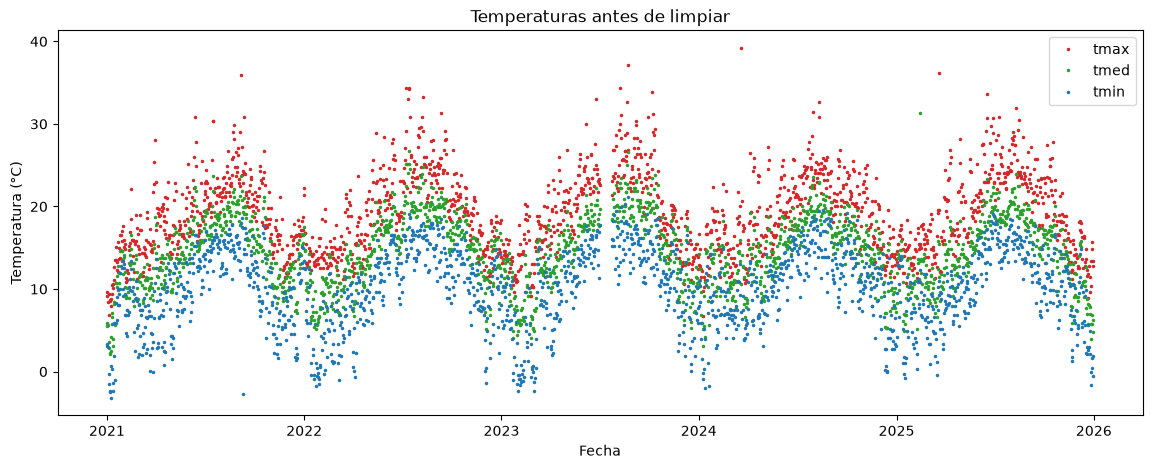

In [9]:
orden = df.sort_values('fecha')

plt.figure(figsize=(14, 5))
plt.plot(orden['fecha'], orden['tmax'], '.', ms=3, color='tab:red', label='tmax')
plt.plot(orden['fecha'], orden['tmed'], '.', ms=3, color='tab:green', label='tmed')
plt.plot(orden['fecha'], orden['tmin'], '.', ms=3, color='tab:blue', label='tmin')
plt.title('Temperaturas antes de limpiar')
plt.xlabel('Fecha')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.show()

En la gráfica se ven **puntos sueltos que no encajan** (más de 30 °C en invierno, una mínima bajo cero en septiembre) y un **hueco en julio de 2023** (faltan días).

## Paso 5. Limpiar

### 5.1 Valores ausentes

In [10]:
df.isna().sum()

fecha      0
tmed      12
tmin      12
tmax      12
hum        0
prec      10
viento     0
pres       1
dtype: int64

**Decisión:** son muy pocos (alrededor del 1 % por variable), así que **se dejan como `NaN`**. No se rellenan porque sería inventar datos, y no se borra la fila entera para no perder las demás variables de ese día. Las medias y sumas de pandas y de SQL ignoran los valores vacíos.

### 5.2 Duplicados y orden

In [11]:
print('Filas duplicadas exactas:', df.duplicated().sum())
print('¿Ordenado por fecha?', df['fecha'].is_monotonic_increasing)

df = df.drop_duplicates()
print('Fechas repetidas con valores distintos:', df['fecha'].duplicated().sum())

# Esas copias están al final del fichero y sus temperaturas difieren de la fila original:
# se conserva la primera aparición (la que está en su sitio en la serie).
df = df.drop_duplicates(subset='fecha', keep='first').sort_values('fecha').reset_index(drop=True)
print('Filas tras eliminar duplicados:', len(df))

Filas duplicadas exactas: 8
¿Ordenado por fecha? False
Fechas repetidas con valores distintos: 5
Filas tras eliminar duplicados: 1799


### 5.3 Días que faltan

Se compara con un calendario completo de 2021 a 2025.

In [12]:
calendario = pd.date_range('2021-01-01', '2025-12-31')
faltan = calendario.difference(df['fecha'])
print('Días que faltan:', len(faltan))
print(faltan.date)

# Se añaden como filas vacías para que los huecos se vean en las gráficas
df = df.set_index('fecha').reindex(calendario).rename_axis('fecha').reset_index()
print('Filas con el calendario completo:', len(df))

Días que faltan: 27
[datetime.date(2021, 2, 17) datetime.date(2021, 5, 25)
 datetime.date(2021, 11, 19) datetime.date(2022, 10, 21)
 datetime.date(2023, 4, 23) datetime.date(2023, 7, 3)
 datetime.date(2023, 7, 4) datetime.date(2023, 7, 5)
 datetime.date(2023, 7, 6) datetime.date(2023, 7, 7)
 datetime.date(2023, 7, 8) datetime.date(2023, 7, 9)
 datetime.date(2023, 7, 10) datetime.date(2023, 7, 11)
 datetime.date(2023, 7, 12) datetime.date(2023, 7, 13)
 datetime.date(2023, 7, 14) datetime.date(2023, 7, 15)
 datetime.date(2023, 7, 16) datetime.date(2023, 7, 17)
 datetime.date(2023, 7, 18) datetime.date(2023, 7, 19)
 datetime.date(2023, 7, 20) datetime.date(2023, 7, 21)
 datetime.date(2023, 7, 22) datetime.date(2023, 7, 23)
 datetime.date(2024, 3, 20)]
Filas con el calendario completo: 1826


Faltan 27 días, la mayoría seguidos en **julio de 2023**. Se añaden como filas vacías y se rellenan más abajo (apartado 5.5).

### 5.4 Valores fuera de rango e inconsistentes

Se comprueba que los valores sean posibles (humedad entre 0 y 100, lluvia no negativa, mínima no mayor que la máxima) y que la temperatura media encaje con la mínima y la máxima. La media de un día debe estar cerca de `(tmin + tmax) / 2`; si se aleja más de 6 °C, alguna de las tres temperaturas está mal.

In [13]:
print('Humedad fuera de 0-100:', ((df['hum'] < 0) | (df['hum'] > 100)).sum())
print('Lluvia negativa:', (df['prec'] < 0).sum())
print('tmin mayor que tmax:', (df['tmin'] > df['tmax']).sum())

no_encaja = (df['tmed'] - (df['tmin'] + df['tmax']) / 2).abs() > 6
print('Días con temperaturas que no encajan:', no_encaja.sum())
df[no_encaja]

Humedad fuera de 0-100: 0
Lluvia negativa: 0
tmin mayor que tmax: 0
Días con temperaturas que no encajan: 4


,fecha,tmed,tmin,tmax,hum,prec,viento,pres
252,2021-09-10,19.3,-2.7,22.9,87.0,1.1,5.8,1018.3
1173,2024-03-19,10.6,7.2,39.2,90.0,0.0,5.2,1016.4
1504,2025-02-13,31.3,12.3,15.2,91.0,2.3,16.6,1018.6
1540,2025-03-21,11.5,9.3,36.2,88.0,17.8,15.1,997.7


Son errores claros (por ejemplo, 39,2 °C de máxima en marzo con 10,6 °C de media). Como no se sabe cuál de las tres temperaturas es la buena, **se anulan las temperaturas de esos días**.

In [14]:
df.loc[no_encaja, ['tmed', 'tmin', 'tmax']] = np.nan
df.describe()

,fecha,tmed,tmin,tmax,hum,prec,viento,pres
count,1826,1783.000000,1783.000000,1783.000000,1799.000000,1789.000000,1799.00000,1798.000000
mean,2023-07-02 12:00:00,14.578239,10.323388,19.186147,80.213452,2.906931,11.93602,1018.179922
min,2021-01-01 00:00:00,2.100000,-3.200000,6.700000,36.000000,0.000000,3.20000,987.900000
25%,2022-04-02 06:00:00,11.400000,7.100000,15.400000,76.000000,0.000000,8.10000,1014.425000
50%,2023-07-02 12:00:00,14.700000,10.900000,18.900000,81.000000,0.000000,10.30000,1018.500000
75%,2024-09-30 18:00:00,18.000000,14.000000,22.800000,86.000000,2.900000,14.90000,1022.500000
max,2025-12-31 00:00:00,26.700000,21.100000,37.200000,100.000000,58.700000,38.50000,1037.900000
std,NaN,4.328440,4.772800,4.857659,8.088499,6.062205,5.23058,7.357177


### 5.5 Rellenar los días que faltan

Los 27 días que no existen en el fichero dejan huecos en las gráficas (sobre todo el de julio de 2023). Para estos días **se usa la media del mismo día del año en los demás años** (pasados y posteriores). Se hace después de limpiar los errores, para que esas medias no usen valores erróneos.

- Solo se rellenan los **días completos que faltaban**; los `NaN` sueltos de una variable se dejan como están (apartado 5.1).
- **No se rellena `prec`**: la lluvia de un día no se parece a la de otros años, y una media inventaría días de lluvia (afectaría al conteo de días de lluvia).
- Se añade la columna `imputado` para saber qué filas no son medidas reales.

In [15]:
VARIABLES = ['tmed', 'tmin', 'tmax', 'hum', 'viento', 'pres']

df['imputado'] = df['fecha'].isin(faltan)

# Media de cada variable para cada día del año (mes y día), con todos los años
dia_del_anio = [df['fecha'].dt.month, df['fecha'].dt.day]
media_dia = df[~df['imputado']].groupby([df['fecha'].dt.month, df['fecha'].dt.day])[VARIABLES].mean()

valores = media_dia.reindex(pd.MultiIndex.from_arrays(dia_del_anio)).set_index(df.index)
df.loc[df['imputado'], VARIABLES] = valores.loc[df['imputado']]

print('Días rellenados:', df['imputado'].sum())
df[df['imputado']].head()

Días rellenados: 27


,fecha,tmed,tmin,tmax,hum,prec,viento,pres,imputado
47,2021-02-17,11.600,7.250,17.300,81.75,NaN,9.775,1025.800,True
144,2021-05-25,16.000,10.700,20.875,76.50,NaN,12.100,1021.125,True
322,2021-11-19,12.600,10.350,15.075,88.75,NaN,7.625,1021.400,True
658,2022-10-21,15.975,12.050,19.400,81.75,NaN,12.600,1015.450,True
842,2023-04-23,12.950,8.525,16.975,77.00,NaN,11.475,1015.700,True


## Paso 6. Guardar los datos limpios

En `datos/clean/` y en UTF-8.

In [16]:
df.to_csv(CLEAN, index=False, encoding='utf-8')
print('Guardado en', CLEAN)

Guardado en ../datos/clean/meteo_alvedro_limpio.csv


## Paso 7. Analizar

In [17]:
df['anio'] = df['fecha'].dt.year
df['mes'] = df['fecha'].dt.month
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto',
         'septiembre', 'octubre', 'noviembre', 'diciembre']

### Pregunta 1. ¿Cuál fue la temperatura media de cada año? ¿Hay tendencia?

In [18]:
media_anual = df.groupby('anio')['tmed'].mean()
print(media_anual.round(2))
print()
print(f'Interpretación: la media anual va de {media_anual.min():.2f} °C ({media_anual.idxmin()}) '
      f'a {media_anual.max():.2f} °C ({media_anual.idxmax()}). La diferencia es pequeña y con solo 5 años '
      f'no se puede hablar de una tendencia.')

anio
2021    14.10
2022    14.98
2023    15.15
2024    14.46
2025    14.46
Name: tmed, dtype: float64

Interpretación: la media anual va de 14.10 °C (2021) a 15.15 °C (2023). La diferencia es pequeña y con solo 5 años no se puede hablar de una tendencia.


### Pregunta 2. ¿Cuál es, de media, el mes más lluvioso y el más seco?

Se suma la lluvia de cada mes de cada año y después se hace la media de cada mes. Nota: la lluvia de los días que faltaban (julio de 2023) no se rellena, así que ese mes sale más bajo de lo real.

In [19]:
lluvia_mensual = df.groupby(['anio', 'mes'])['prec'].sum(min_count=1)
lluvia_media_mes = lluvia_mensual.groupby('mes').mean()
print(lluvia_media_mes.round(1))
print()
print(f'Interpretación: el mes más lluvioso es {MESES[lluvia_media_mes.idxmax() - 1]} '
      f'({lluvia_media_mes.max():.1f} mm) y el más seco {MESES[lluvia_media_mes.idxmin() - 1]} '
      f'({lluvia_media_mes.min():.1f} mm).')

mes
1     125.8
2      95.5
3      85.4
4      81.9
5      65.9
6      50.4
7      13.4
8      13.4
9      73.0
10    147.1
11    152.1
12    136.1
Name: prec, dtype: float64

Interpretación: el mes más lluvioso es noviembre (152.1 mm) y el más seco agosto (13.4 mm).


### Pregunta 3. ¿Cuántos días de lluvia hay cada mes?

**Criterio:** día de lluvia = día con **1 mm o más**.

In [20]:
df['dia_lluvia'] = df['prec'] >= 1
dias_lluvia = df.groupby(['anio', 'mes'])['dia_lluvia'].sum().unstack()
display(dias_lluvia)

media_dias = dias_lluvia.mean()
print(f'Interpretación: de media, {MESES[media_dias.idxmax() - 1]} es el mes con más días de lluvia '
      f'({media_dias.max():.1f}) y {MESES[media_dias.idxmin() - 1]} el que menos ({media_dias.min():.1f}).')

mes,1,2,3,4,5,6,7,8,9,10,11,12
anio,,,,,,,,,,,,
2021,17,14,6,10,16,10,8,3,13,12,11,14
2022,6,6,16,11,6,10,1,2,11,15,20,16
2023,15,6,9,6,5,10,3,6,11,19,17,17
2024,12,13,17,10,15,5,7,6,11,19,11,9
2025,20,13,10,12,8,6,4,5,12,8,21,16


Interpretación: de media, noviembre es el mes con más días de lluvia (16.0) y agosto el que menos (4.4).


### Pregunta 4. ¿Cuál fue el día más cálido y el más frío de cada año?

Más cálido según la temperatura máxima y más frío según la mínima.

In [21]:
mas_calido = df.loc[df.groupby('anio')['tmax'].idxmax(), ['anio', 'fecha', 'tmax']]
mas_frio = df.loc[df.groupby('anio')['tmin'].idxmin(), ['anio', 'fecha', 'tmin']]

extremos = mas_calido.merge(mas_frio, on='anio', suffixes=('_calido', '_frio'))
display(extremos)
print('Interpretación: los días más cálidos caen en verano y los más fríos en invierno, '
      'con una diferencia moderada propia del clima de costa.')

,anio,fecha_calido,tmax,fecha_frio,tmin
0,2021,2021-09-06,35.9,2021-01-08,-3.2
1,2022,2022-07-14,34.4,2022-01-23,-1.8
2,2023,2023-08-23,37.2,2023-01-31,-2.3
3,2024,2024-08-11,32.6,2024-01-12,-2.0
4,2025,2025-06-18,33.6,2025-12-27,-1.6


Interpretación: los días más cálidos caen en verano y los más fríos en invierno, con una diferencia moderada propia del clima de costa.


## Paso 8. Gráficas

### Temperatura diaria con media móvil de 30 días

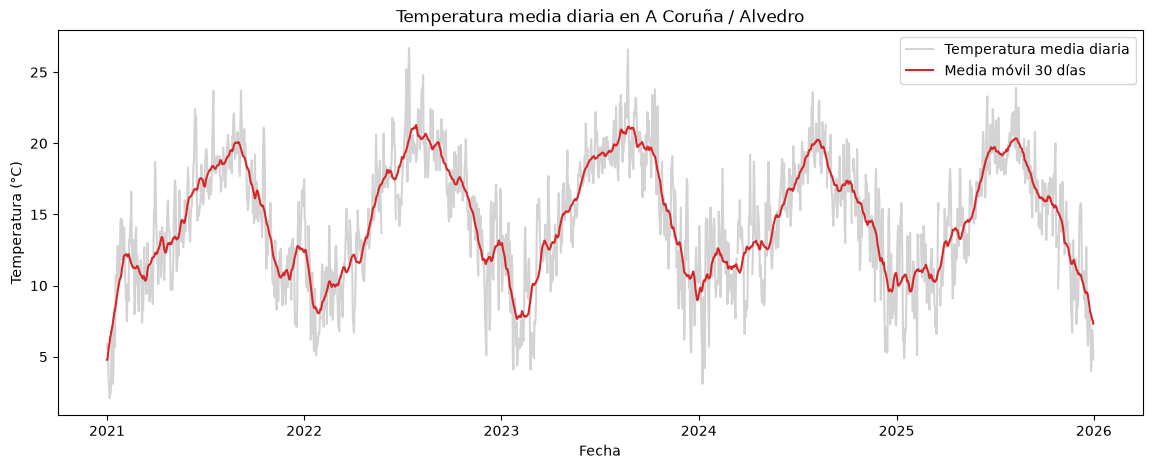

In [22]:
media_movil = df['tmed'].rolling(30, center=True, min_periods=15).mean()

plt.figure(figsize=(14, 5))
plt.plot(df['fecha'], df['tmed'], color='lightgray', label='Temperatura media diaria')
plt.plot(df['fecha'], media_movil, color='tab:red', label='Media móvil 30 días')
plt.title('Temperatura media diaria en A Coruña / Alvedro')
plt.xlabel('Fecha')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.savefig(OUTPUT / '01_temperatura_diaria.png')
plt.show()

### Precipitación mensual

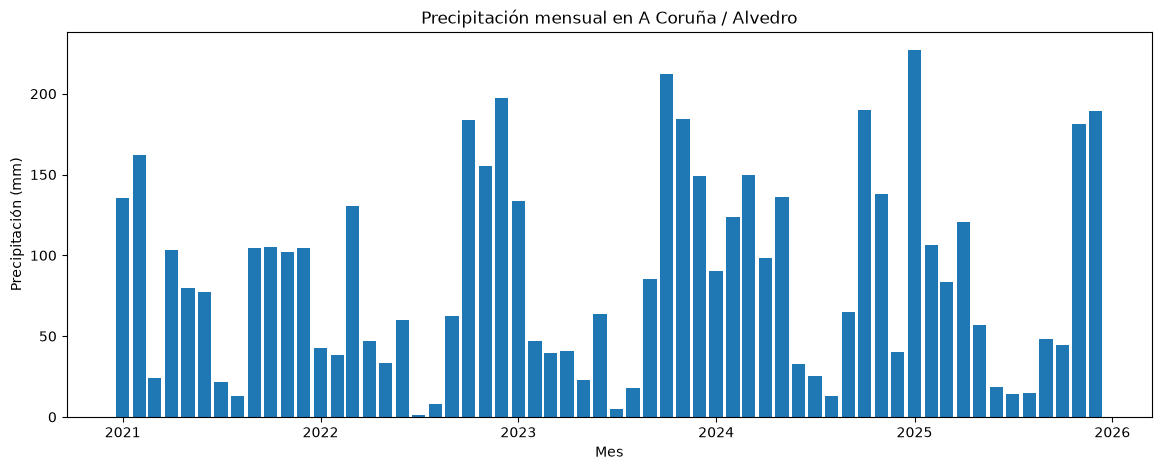

In [23]:
lluvia_por_mes = df.set_index('fecha')['prec'].resample('MS').sum()

plt.figure(figsize=(14, 5))
plt.bar(lluvia_por_mes.index, lluvia_por_mes.values, width=25, color='tab:blue')
plt.title('Precipitación mensual en A Coruña / Alvedro')
plt.xlabel('Mes')
plt.ylabel('Precipitación (mm)')
plt.savefig(OUTPUT / '02_precipitacion_mensual.png')
plt.show()

### Último año comparado con la media de los anteriores

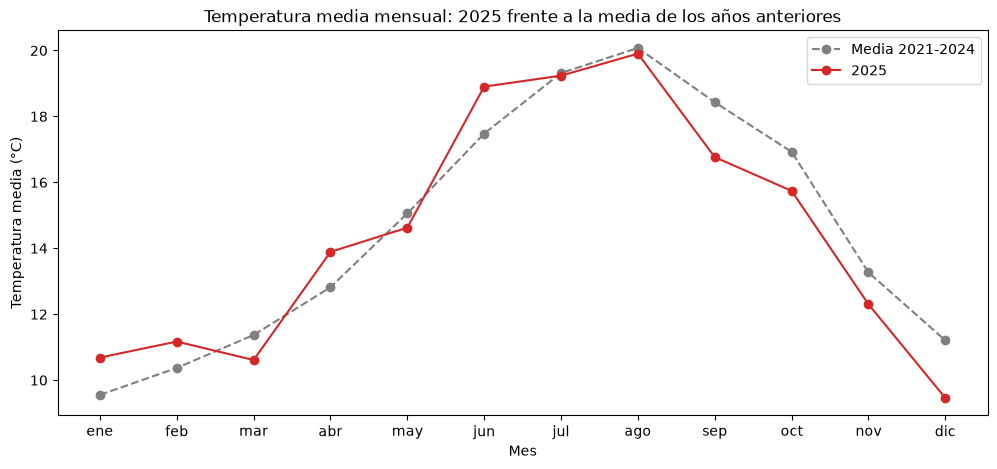

In [24]:
temp_mensual = df.groupby(['anio', 'mes'])['tmed'].mean().unstack('anio')
ultimo = temp_mensual.columns.max()

plt.figure(figsize=(12, 5))
plt.plot(temp_mensual.index, temp_mensual.drop(columns=ultimo).mean(axis=1), 'o--', color='gray', label='Media 2021-2024')
plt.plot(temp_mensual.index, temp_mensual[ultimo], 'o-', color='tab:red', label=str(ultimo))
plt.xticks(range(1, 13), [m[:3] for m in MESES])
plt.title(f'Temperatura media mensual: {ultimo} frente a la media de los años anteriores')
plt.xlabel('Mes')
plt.ylabel('Temperatura media (°C)')
plt.legend()
plt.savefig(OUTPUT / '03_ultimo_anio.png')
plt.show()

## Paso 9. Eficiencia

Amplitud térmica diaria (`tmax - tmin`) con un bucle `for` y con una operación vectorizada.

In [25]:
def amplitud_bucle(datos):
    resultado = []
    for _, fila in datos.iterrows():
        resultado.append(fila['tmax'] - fila['tmin'])
    return resultado

def amplitud_vectorizada(datos):
    return datos['tmax'] - datos['tmin']

print(f'DataFrame original: {len(df)} filas')
%timeit amplitud_bucle(df)
%timeit amplitud_vectorizada(df)

DataFrame original: 1826 filas
66 ms ± 1.42 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
67.6 μs ± 1.64 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [26]:
grande = pd.concat([df] * 5, ignore_index=True)

print(f'DataFrame 5 veces más grande: {len(grande)} filas')
%timeit amplitud_bucle(grande)
%timeit amplitud_vectorizada(grande)

DataFrame 5 veces más grande: 9130 filas
331 ms ± 7.04 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
72.2 μs ± 1.78 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


**Qué se observa:** la versión vectorizada es unas mil veces más rápida (62 ms frente a 62 µs). Con 5 veces más filas, el bucle tarda unas 5 veces más, mientras que la versión vectorizada casi no cambia. El bucle procesa las filas una a una en Python, y la operación vectorizada hace la resta de toda la columna de una vez con código compilado de NumPy.

## Paso 10. PostgreSQL

**Antes:** tener Docker Desktop en marcha y el fichero `.env` en la raíz del proyecto (si no existe, copiar `.env.example` como `.env`).

Levantar PostgreSQL con Docker:

In [27]:
!docker compose -f ../docker-compose.yml up -d

[+] up 0/1
 ⠋ Network task-p1-que-tiempo-hizo-_default Creating                        0.0s
[+] up 1/2
 ✔ Network task-p1-que-tiempo-hizo-_default Created                         0.0s
 ⠋ Container meteo-postgres                 Creating                        0.1s
[+] up 1/2
 ✔ Network task-p1-que-tiempo-hizo-_default Created                         0.0s
 ⠙ Container meteo-postgres                 Starting                        0.2s
[+] up 1/2
 ✔ Network task-p1-que-tiempo-hizo-_default Created                         0.0s
 ⠹ Container meteo-postgres                 Starting                        0.3s
[+] up 2/2
 ✔ Network task-p1-que-tiempo-hizo-_default Created                         0.0s
 ✔ Container meteo-postgres                 Started                         0.3s


Conectar con las credenciales del `.env` y cargar la tabla limpia con `to_sql`:

In [28]:
import os
import time
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv(RAIZ / '.env')
motor = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@{os.getenv('POSTGRES_HOST', 'localhost')}:{os.getenv('POSTGRES_PORT', '5432')}/{os.environ['POSTGRES_DB']}"
)

# PostgreSQL tarda unos segundos en arrancar: se reintenta la conexión
for intento in range(30):
    try:
        with motor.connect():
            print('Conectado a PostgreSQL')
        break
    except Exception:
        time.sleep(2)

limpio = pd.read_csv(CLEAN, parse_dates=['fecha'])
limpio.to_sql('meteo', motor, if_exists='replace', index=False)
print('Filas cargadas:', pd.read_sql('SELECT COUNT(*) FROM meteo', motor).iloc[0, 0])

Conectado a PostgreSQL
Filas cargadas: 1826


### SQL · Pregunta 1: temperatura media de cada año

In [29]:
q1 = pd.read_sql('''
    SELECT EXTRACT(YEAR FROM fecha) AS anio, AVG(tmed) AS tmed_media
    FROM meteo
    GROUP BY anio
    ORDER BY anio
''', motor)
display(q1)
print('¿Coincide con pandas?', np.allclose(q1['tmed_media'], media_anual.values))

,anio,tmed_media
0,2021.0,14.096953
1,2022.0,14.979821
2,2023.0,15.148151
3,2024.0,14.455625
4,2025.0,14.457064


¿Coincide con pandas? True


### SQL · Pregunta 2: lluvia media de cada mes

In [30]:
q2 = pd.read_sql('''
    WITH mensual AS (
        SELECT EXTRACT(YEAR FROM fecha) AS anio,
               EXTRACT(MONTH FROM fecha) AS mes,
               SUM(prec) AS total
        FROM meteo
        GROUP BY anio, mes
    )
    SELECT mes, AVG(total) AS lluvia_media
    FROM mensual
    GROUP BY mes
    ORDER BY mes
''', motor)
display(q2)
print('¿Coincide con pandas?', np.allclose(q2['lluvia_media'], lluvia_media_mes.values))

,mes,lluvia_media
0,1.0,125.84
1,2.0,95.46
2,3.0,85.38
3,4.0,81.88
4,5.0,65.88
5,6.0,50.44
6,7.0,13.44
7,8.0,13.42
8,9.0,73.00
9,10.0,147.14


¿Coincide con pandas? True


### SQL · Pregunta nueva: ¿cuántos días de calor (máxima de 25 °C o más) hubo cada año?

In [31]:
q3 = pd.read_sql('''
    SELECT EXTRACT(YEAR FROM fecha) AS anio,
           COUNT(*) FILTER (WHERE tmax >= 25) AS dias_calor
    FROM meteo
    GROUP BY anio
    ORDER BY anio
''', motor)
display(q3)

dias_calor_pandas = (df['tmax'] >= 25).groupby(df['anio']).sum()
print('¿Coincide con pandas?', (q3['dias_calor'].values == dias_calor_pandas.values).all())

,anio,dias_calor
0,2021.0,25
1,2022.0,51
2,2023.0,61
3,2024.0,27
4,2025.0,49


¿Coincide con pandas? True


In [32]:
# Al terminar, parar PostgreSQL
!docker compose -f ../docker-compose.yml down

[+] down 0/1
 ⠋ Container meteo-postgres Stopping                                        0.1s
[+] down 0/1
 ⠙ Container meteo-postgres Stopping                                        0.2s
[+] down 0/1
 ⠹ Container meteo-postgres Stopping                                        0.3s
[+] down 1/2
 ✔ Container meteo-postgres                 Removed                         0.3s
 ⠋ Network task-p1-que-tiempo-hizo-_default Removing                        0.0s
[+] down 1/2
 ✔ Container meteo-postgres                 Removed                         0.3s
 ⠙ Network task-p1-que-tiempo-hizo-_default Removing                        0.1s
[+] down 1/2
 ✔ Container meteo-postgres                 Removed                         0.3s
 ⠹ Network task-p1-que-tiempo-hizo-_default Removing                        0.2s
[+] down 2/2
 ✔ Container meteo-postgres                 Removed                         0.3s
 ✔ Network task-p1-que-tiempo-hizo-_default Removed                         0.2s
